✅ Veri yüklendi:
   ID                                              Entry OriginalEmotion  \
0   1                          her yeni gün bir mutluluk           Happy   
1   2  gece kimsenin olmadığı sokaklardan geçerken ço...            Fear   
2   3                           gerçekleşemeyen hayaller           Anger   
3   4                      arkadaş kaybetmek beni üzüyor         Sadness   
4   5       insanların çıkarcı olmalarından tiksiniyorum         Disgust   

  ValidatedEmotion  Condition           VoteDistribution  
0            Happy  Consensus        Happy, Happy, Happy  
1             Fear  Consensus           Fear, Fear, Fear  
2          Sadness  Consensus  Sadness, Sadness, Sadness  
3          Sadness  Consensus  Sadness, Sadness, Sadness  
4          Disgust  Consensus  Disgust, Disgust, Disgust  

🔍 Eksik değer sayısı:
ID                  0
Entry               0
OriginalEmotion     0
ValidatedEmotion    0
Condition           0
VoteDistribution    0
dtype: int64

📋 S

/tmp/ipykernel_8741/501085489.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='ValidatedEmotion', palette='pastel')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127917 (\N{PERFORMING ARTS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


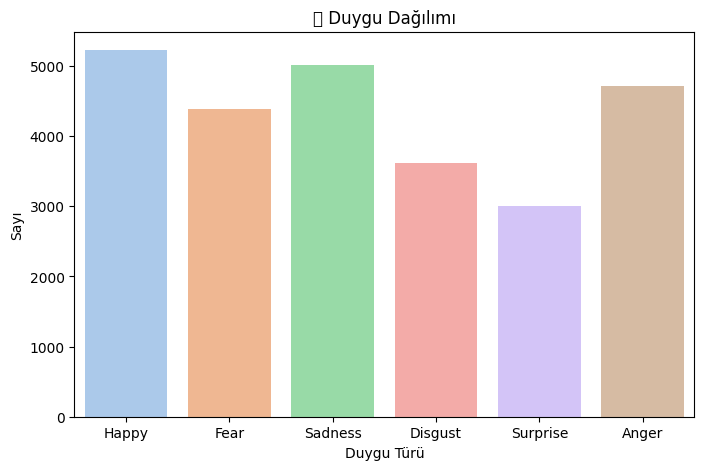


🔸 Mevcut duygu sınıfları:
ValidatedEmotion
Happy       5229
Sadness     5021
Anger       4723
Fear        4393
Disgust     3620
Surprise    3003
Name: count, dtype: int64


In [ ]:
# ==========================================
# 💫 1. VERİ HAZIRLIĞI (TREMODATA)
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.unicode.east_asian_width', True)

DATA_PATH = "TREMODATA (1).csv"
df = pd.read_csv(DATA_PATH)

print("✅ Veri yüklendi:")
print(df.head())

print("\n🔍 Eksik değer sayısı:")
print(df.isnull().sum())

print("\n📋 Sütunlar:", df.columns.tolist())

if 'Entry' in df.columns and 'ValidatedEmotion' in df.columns:
    df = df[['Entry', 'ValidatedEmotion']]
else:
    print("\n⚠️ Lütfen sütun isimlerini kontrol et — farklı adlandırılmış olabilir.")

df.dropna(inplace=True)

df = df[df['ValidatedEmotion'] != 'Ambigious']
print("\n🧹 'Ambigious' sınıfı veri setinden çıkarıldı.")

print(f"\n📊 Temizlenmiş veri boyutu: {df.shape}")

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='ValidatedEmotion', palette='pastel')
plt.title("🎭 Duygu Dağılımı")
plt.xlabel("Duygu Türü")
plt.ylabel("Sayı")
plt.show()

print("\n🔸 Mevcut duygu sınıfları:")
print(df['ValidatedEmotion'].value_counts())


In [ ]:
# ==========================================
# 💫 2. VERİ HAZIRLIĞI (TRAIN / VAL / TEST)
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from transformers import BertTokenizer

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["ValidatedEmotion"])

train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    df["Entry"].tolist(),
    df["label"].tolist(),
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print(f"✅ Veri Bölme Tamamlandı:")
print(f"📊 Eğitim (Train): {len(train_texts)}")
print(f"📊 Doğrulama (Val): {len(val_texts)}")
print(f"📊 Test (Test): {len(test_texts)}")

tokenizer = BertTokenizer.from_pretrained("dbmdz/bert-base-turkish-cased")

train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=128)
val_encodings = tokenizer(val_texts, truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(test_texts, truncation=True, padding=True, max_length=128)

✅ Veri Bölme Tamamlandı:
📊 Eğitim (Train): 18192
📊 Doğrulama (Val): 3898
📊 Test (Test): 3899


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

In [ ]:
# ==========================================
# 💫 3.MODEL EĞİTİMİ 
# ==========================================

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import BertForSequenceClassification, BertTokenizer
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import classification_report
from tqdm import tqdm
from collections import Counter
import numpy as np
import random
import os


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("✅ Kullanılan cihaz:", device)

def oversample_texts(texts, labels):
    counts = Counter(labels)
    max_count = max(counts.values())
    new_texts, new_labels = [], []

    for label in counts:
        label_texts = [t for t, l in zip(texts, labels) if l == label]
        while len(label_texts) < max_count:
            label_texts.append(random.choice(label_texts))
        new_texts.extend(label_texts)
        new_labels.extend([label]*max_count)
    return new_texts, new_labels

train_texts_bal, train_labels_bal = oversample_texts(train_texts, train_labels)
print(f"🔹 Oversampled eğitim boyutu: {len(train_texts_bal)}")

best_model_path = "turkish_emotion_bert_pytorch_final"

train_encodings = tokenizer(
    train_texts_bal,
    truncation=True,
    padding=True,
    max_length=128
)

val_encodings = tokenizer(
    val_texts,
    truncation=True,
    padding=True,
    max_length=128
)


class EmotionDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = EmotionDataset(train_encodings, train_labels_bal)
val_dataset = EmotionDataset(val_encodings, val_labels)
test_dataset = EmotionDataset(test_encodings, test_labels)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)


num_labels = len(label_encoder.classes_)
model = BertForSequenceClassification.from_pretrained(
    "dbmdz/bert-base-turkish-cased",
    num_labels=num_labels,
    hidden_dropout_prob=0.3,
    attention_probs_dropout_prob=0.3
).to(device)


epochs = 10
optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.1)

total_steps = len(train_loader) * epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=0,
    num_training_steps=total_steps
)

best_val_loss = float('inf')
patience = 3
trigger_times = 0

for epoch in range(epochs):
    
    model.train()
    total_loss = 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1} Train"):
        optimizer.zero_grad()

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss

        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)

   
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
            val_loss += outputs.loss.item()

    avg_val_loss = val_loss / len(val_loader)

    print(f"Epoch {epoch+1} | Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f}")

    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        trigger_times = 0

        model.save_pretrained(best_model_path)
        tokenizer.save_pretrained(best_model_path)
        print(f"🌟 Yeni en iyi model ve sözlük '{best_model_path}' klasörüne kaydedildi.")
    else:
        trigger_times += 1
        if trigger_times >= patience:
            print("⏹ Early stopping! (Model ezberlemeye başladı, eğitim durduruluyor)")
            break

model.eval()
preds, true_labels = [], []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        logits = model(input_ids, attention_mask=attention_mask).logits
        preds.extend(torch.argmax(logits, axis=1).cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

print("\n🏆 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (Objektif Başarı):")
print(classification_report(true_labels, preds, target_names=label_encoder.classes_))

print(f"\n🎉 İşlem Tamamlandı! '{best_model_path}' klasörünü bilgisayarına indirebilirsin.")

✅ Kullanılan cihaz: cuda
🔹 Oversampled eğitim boyutu: 21960


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Epoch 1 Train: 100%|█████

Epoch 1 | Train Loss=0.6099 | Val Loss=0.2869


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Epoch 5 | Train Loss=0.1291 | Val Loss=0.2583


Epoch 6 Train: 100%|██████████| 1373/1373 [07:23<00:00,  3.10it/s]


Epoch 6 | Train Loss=0.1093 | Val Loss=0.2525


Epoch 7 Train: 100%|██████████| 1373/1373 [07:23<00:00,  3.10it/s]


Epoch 7 | Train Loss=0.0911 | Val Loss=0.2597
⏹ Early stopping! (Model ezberlemeye başladı, eğitim durduruluyor)

🏆 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (Objektif Başarı):
              precision    recall  f1-score   support

       Anger       0.93      0.92      0.93       709
     Disgust       0.94      0.94      0.94       543
        Fear       0.93      0.93      0.93       659
       Happy       0.94      0.96      0.95       785
     Sadness       0.92      0.93      0.93       753
    Surprise       0.92      0.87      0.90       450

    accuracy                           0.93      3899
   macro avg       0.93      0.93      0.93      3899
weighted avg       0.93      0.93      0.93      3899


🎉 İşlem Tamamlandı! 'turkish_emotion_bert_pytorch_final' klasörünü bilgisayarına indirebilirsin.


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


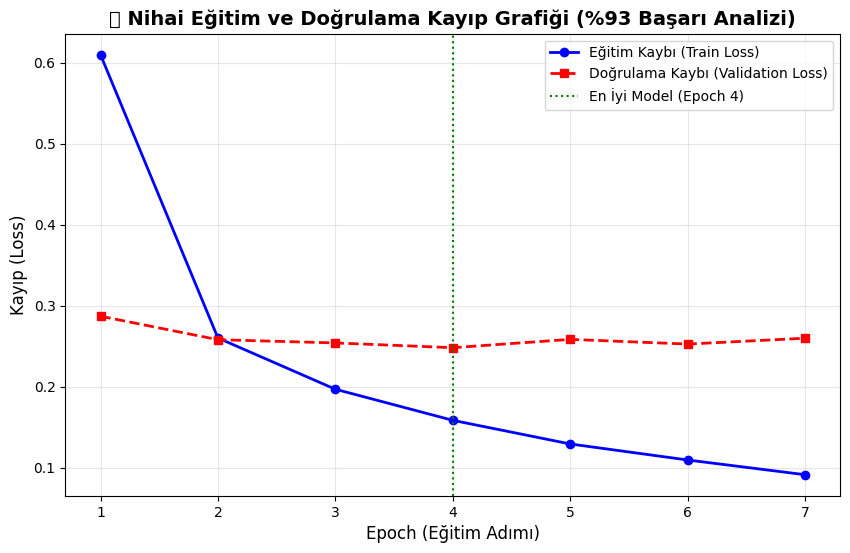

In [ ]:
import matplotlib.pyplot as plt

epochs = [1, 2, 3, 4, 5, 6, 7]

train_losses = [0.6099, 0.2600, 0.1967, 0.1583, 0.1291, 0.1093, 0.0911]

val_losses   = [0.2869, 0.2579, 0.2539, 0.2480, 0.2583, 0.2525, 0.2597]

plt.figure(figsize=(10, 6))

# Eğitim Kaybı (Train Loss)
plt.plot(epochs, train_losses, label='Eğitim Kaybı (Train Loss)',
         color='blue', marker='o', linestyle='-', linewidth=2)

# Doğrulama Kaybı (Validation Loss)
plt.plot(epochs, val_losses, label='Doğrulama Kaybı (Validation Loss)',
         color='red', marker='s', linestyle='--', linewidth=2)

plt.axvline(x=4, color='green', linestyle=':', label='En İyi Model (Epoch 4)')

plt.title("📉 Nihai Eğitim ve Doğrulama Kayıp Grafiği (%93 Başarı Analizi)", fontsize=14, fontweight='bold')
plt.xlabel("Epoch (Eğitim Adımı)", fontsize=12)
plt.ylabel("Kayıp (Loss)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

/tmp/ipykernel_8741/1503314595.py:56: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


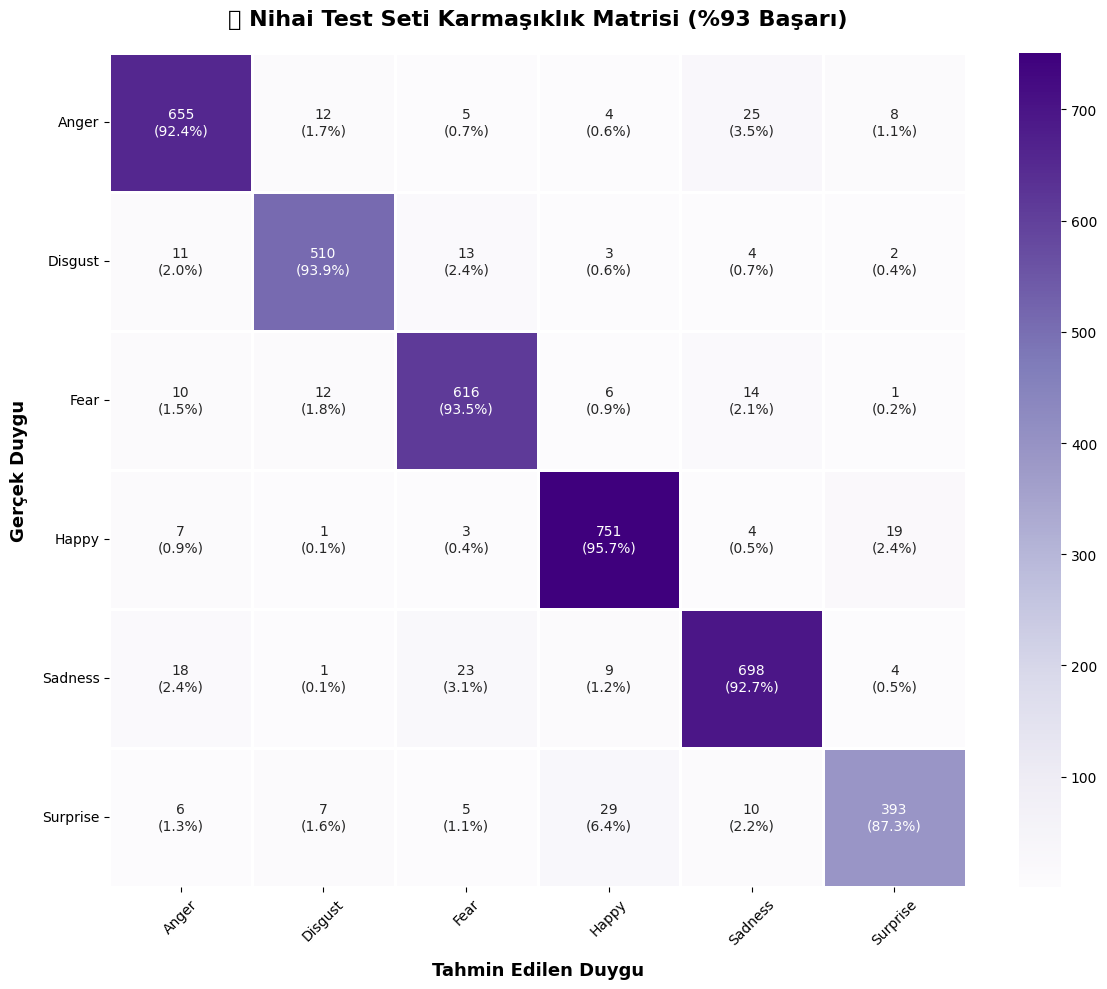

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import torch

y_pred = []
y_true = []

model.eval()
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        y_pred.extend(preds.cpu().numpy())
        y_true.extend(labels.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)
emotion_labels = label_encoder.classes_

plt.figure(figsize=(12, 10))

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

annot_labels = []
for i in range(len(emotion_labels)):
    for j in range(len(emotion_labels)):
        count = cm[i, j]
        pct = cm_normalized[i, j]
        annot_labels.append(f"{count}\n({pct:.1%})")

annot_labels = np.asarray(annot_labels).reshape(len(emotion_labels), len(emotion_labels))

sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Purples',
            xticklabels=emotion_labels,
            yticklabels=emotion_labels,
            cbar=True,
            linewidths=1, linecolor='white')

plt.title("📈 Nihai Test Seti Karmaşıklık Matrisi (%93 Başarı)", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Tahmin Edilen Duygu", fontsize=13, fontweight='bold', labelpad=10)
plt.ylabel("Gerçek Duygu", fontsize=13, fontweight='bold', labelpad=10)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
from transformers import BertTokenizer
import torch
import torch.nn.functional as F

tokenizer = BertTokenizer.from_pretrained("dbmdz/bert-base-turkish-cased")

test_sentences = [
    "Bugün harika bir gün, kendimi çok mutlu hissediyorum!",
    "Kimse beni anlamıyor, içimde tarif edilemez bir boşluk var...",
    "Yine o karanlık sokaklardan geçmekten korkuyorum.",
    "İnsanların bu kadar bencil olması tepemin tasını attırıyor.",
    "Iyy, bu yemeğin içinden ne çıktı böyle!",
    "O kadar şaşırdım ki ne diyeceğimi bilemedim, nutkum tutuldu.",
    "Sınavdan düşük aldım ama en azından dersi geçtim."
]

model.eval()

emoji_map = {
    "Happy": "😊",
    "Sadness": "😔",
    "Fear": "😨",
    "Anger": "😠",
    "Disgust": "🤢",
    "Surprise": "😲"
}

print(f"{'CÜMLE':<60} | {'TAHMİN':<15} | {'GÜVEN (%)':<10}")
print("-" * 95)

for sentence in test_sentences:
    
    inputs = tokenizer(sentence, return_tensors="pt", truncation=True, padding=True, max_length=128).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=1)
        max_prob, pred_idx = torch.max(probs, dim=1)

        pred_label_idx = pred_idx.item()
        confidence = max_prob.item() * 100

        emotion = label_encoder.inverse_transform([pred_label_idx])[0]

    if confidence < 60:
        display_emotion = "Karmaşık 🤔"
    else:
        icon = emoji_map.get(emotion, "✨")
        display_emotion = f"{emotion} {icon}"

    
    clean_sentence = sentence if len(sentence) < 58 else sentence[:55] + "..."
    print(f"{clean_sentence:<60} | {display_emotion:<15} | %{confidence:.2f}")

CÜMLE                                                        | TAHMİN          | GÜVEN (%) 
-----------------------------------------------------------------------------------------------
Bugün harika bir gün, kendimi çok mutlu hissediyorum!        | Happy 😊         | %99.96
Kimse beni anlamıyor, içimde tarif edilemez bir boşluk ...   | Sadness 😔       | %94.36
Yine o karanlık sokaklardan geçmekten korkuyorum.            | Fear 😨          | %99.96
İnsanların bu kadar bencil olması tepemin tasını attırı...   | Anger 😠         | %99.87
Iyy, bu yemeğin içinden ne çıktı böyle!                      | Disgust 🤢       | %99.96
O kadar şaşırdım ki ne diyeceğimi bilemedim, nutkum tut...   | Surprise 😲      | %99.97
Sınavdan düşük aldım ama en azından dersi geçtim.            | Happy 😊         | %95.68


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df["ValidatedEmotion"])
X = df["Entry"].astype(str).tolist()

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded, test_size=0.30, random_state=42, stratify=y_encoded
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

tfidf = TfidfVectorizer(max_features=10000)

X_train_tfidf = tfidf.fit_transform(X_train_raw)

X_val_tfidf = tfidf.transform(X_val_raw)
X_test_tfidf = tfidf.transform(X_test_raw)

print("✅ ML Modelleri için 3'lü Bölme ve TF-IDF Tamamlandı!")
print(f"📊 Eğitim Seti: {X_train_tfidf.shape[0]}")
print(f"📊 Doğrulama Seti: {X_val_tfidf.shape[0]}")
print(f"📊 Test Seti: {X_test_tfidf.shape[0]}")

✅ ML Modelleri için 3'lü Bölme ve TF-IDF Tamamlandı!
📊 Eğitim Seti: 18192
📊 Doğrulama Seti: 3898
📊 Test Seti: 3899


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_tfidf, y_train)

y_pred_knn = knn.predict(X_test_tfidf)

acc_knn = accuracy_score(y_test, y_pred_knn)

print(f"🏆 KNN NİHAİ TEST DOĞRULUĞU (Accuracy): %{acc_knn*100:.2f}")
print("\n📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (KNN):")
print("-" * 60)
print(classification_report(y_test, y_pred_knn, target_names=label_encoder.classes_))

🏆 KNN NİHAİ TEST DOĞRULUĞU (Accuracy): %51.86

📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (KNN):
------------------------------------------------------------
              precision    recall  f1-score   support

       Anger       0.45      0.52      0.48       709
     Disgust       0.61      0.59      0.60       543
        Fear       0.69      0.55      0.62       659
       Happy       0.38      0.76      0.51       785
     Sadness       0.80      0.38      0.52       753
    Surprise       0.82      0.20      0.32       450

    accuracy                           0.52      3899
   macro avg       0.62      0.50      0.51      3899
weighted avg       0.61      0.52      0.51      3899



In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

svm = LinearSVC(random_state=42)
svm.fit(X_train_tfidf, y_train)

y_pred_svm = svm.predict(X_test_tfidf)

acc_svm = accuracy_score(y_test, y_pred_svm)

print(f"🏆 SVM NİHAİ TEST DOĞRULUĞU (Accuracy): %{acc_svm*100:.2f}")
print("\n📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (SVM):")
print("-" * 60)
print(classification_report(y_test, y_pred_svm, target_names=label_encoder.classes_))

🏆 SVM NİHAİ TEST DOĞRULUĞU (Accuracy): %86.87

📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (SVM):
------------------------------------------------------------
              precision    recall  f1-score   support

       Anger       0.84      0.89      0.86       709
     Disgust       0.91      0.90      0.90       543
        Fear       0.92      0.89      0.90       659
       Happy       0.84      0.87      0.86       785
     Sadness       0.85      0.84      0.84       753
    Surprise       0.88      0.83      0.85       450

    accuracy                           0.87      3899
   macro avg       0.87      0.87      0.87      3899
weighted avg       0.87      0.87      0.87      3899



In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Bidirectional, Dropout
from sklearn.metrics import classification_report, accuracy_score
import numpy as np


VOCAB_SIZE = 10000
MAX_LEN = 128
EMBEDDING_DIM = 100
EPOCHS = 10
BATCH_SIZE = 32

print("🔄 LSTM için veri hazırlanıyor...")

tokenizer_lstm = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer_lstm.fit_on_texts(train_texts)

train_seq = tokenizer_lstm.texts_to_sequences(train_texts)
val_seq = tokenizer_lstm.texts_to_sequences(val_texts)
test_seq = tokenizer_lstm.texts_to_sequences(test_texts)

train_padded = pad_sequences(train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
val_padded = pad_sequences(val_seq, maxlen=MAX_LEN, padding='post', truncating='post')
test_padded = pad_sequences(test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

y_train_np = np.array(train_labels)
y_val_np = np.array(val_labels)
y_test_np = np.array(test_labels)

print("✅ Veri 3'lü bölme formatında hazırlandı.")

model_lstm = Sequential([
    Embedding(VOCAB_SIZE, EMBEDDING_DIM, input_length=MAX_LEN),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(32)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(6, activation='softmax')
])

model_lstm.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

print("\n🚀 LSTM Eğitimi Başlıyor...")
history = model_lstm.fit(
    train_padded, y_train_np,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(val_padded, y_val_np),
    callbacks=[early_stop],
    verbose=1
)

print("\n📊 LSTM Nihai Test Sonuçları Hesaplanıyor...")

y_pred_probs = model_lstm.predict(test_padded)
y_pred_lstm = np.argmax(y_pred_probs, axis=1)

acc_lstm = accuracy_score(y_test_np, y_pred_lstm)
print(f"\n🏆 LSTM NİHAİ TEST DOĞRULUĞU: %{acc_lstm*100:.2f}")
print(classification_report(y_test_np, y_pred_lstm, target_names=label_encoder.classes_))

🔄 LSTM için veri hazırlanıyor...
✅ Veri 3'lü bölme formatında hazırlandı.

🚀 LSTM Eğitimi Başlıyor...
Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


569/569 ━━━━━━━━━━━━━━━━━━━━ 23s 25ms/step - accuracy: 0.6494 - loss: 0.9129 - val_accuracy: 0.8307 - val_loss: 0.5006
Epoch 2/10
569/569 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - accuracy: 0.8958 - loss: 0.3215 - val_accuracy: 0.8561 - val_loss: 0.4326
Epoch 3/10
569/569 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - accuracy: 0.9417 - loss: 0.1881 - val_accuracy: 0.8512 - val_loss: 0.4841
Epoch 4/10
569/569 ━━━━━━━━━━━━━━━━━━━━ 14s 25ms/step - accuracy: 0.9576 - loss: 0.1321 - val_accuracy: 0.8522 - val_loss: 0.5308
Epoch 5/10
569/569 ━━━━━━━━━━━━━━━━━━━━ 17s 29ms/step - accuracy: 0.9642 - loss: 0.1076 - val_accuracy: 0.8466 - val_loss: 0.5804

📊 LSTM Nihai Test Sonuçları Hesaplanıyor...
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step

🏆 LSTM NİHAİ TEST DOĞRULUĞU: %86.43
              precision    recall  f1-score   support

       Anger       0.86      0.87      0.86       709
     Disgust       0.90      0.88      0.89       543
        Fear       0.88      0.90      0.89       659
       Happy       0

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_tfidf, y_train)

y_pred_lr = lr.predict(X_test_tfidf)

acc_lr = accuracy_score(y_test, y_pred_lr)

print(f"🏆 Logistic Regression NİHAİ TEST DOĞRULUĞU (Accuracy): %{acc_lr*100:.2f}")
print("\n📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (Logistic Regression):")
print("-" * 60)
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

🏆 Logistic Regression NİHAİ TEST DOĞRULUĞU (Accuracy): %86.56

📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (Logistic Regression):
------------------------------------------------------------
              precision    recall  f1-score   support

       Anger       0.82      0.90      0.86       709
     Disgust       0.92      0.87      0.90       543
        Fear       0.92      0.88      0.90       659
       Happy       0.83      0.88      0.86       785
     Sadness       0.83      0.84      0.84       753
    Surprise       0.93      0.81      0.87       450

    accuracy                           0.87      3899
   macro avg       0.88      0.86      0.87      3899
weighted avg       0.87      0.87      0.87      3899



In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)

y_pred_nb = nb.predict(X_test_tfidf)

acc_nb = accuracy_score(y_test, y_pred_nb)

print(f"🏆 Naive Bayes NİHAİ TEST DOĞRULUĞU (Accuracy): %{acc_nb*100:.2f}")
print("\n📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (Naive Bayes):")
print("-" * 60)
print(classification_report(y_test, y_pred_nb, target_names=label_encoder.classes_))

🏆 Naive Bayes NİHAİ TEST DOĞRULUĞU (Accuracy): %84.48

📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (Naive Bayes):
------------------------------------------------------------
              precision    recall  f1-score   support

       Anger       0.84      0.89      0.86       709
     Disgust       0.92      0.87      0.89       543
        Fear       0.91      0.85      0.88       659
       Happy       0.77      0.90      0.83       785
     Sadness       0.81      0.82      0.82       753
    Surprise       0.91      0.68      0.78       450

    accuracy                           0.84      3899
   macro avg       0.86      0.83      0.84      3899
weighted avg       0.85      0.84      0.84      3899



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt = DecisionTreeClassifier(random_state=42, max_depth=50)
dt.fit(X_train_tfidf, y_train)
 
y_pred_dt = dt.predict(X_test_tfidf)

acc_dt = accuracy_score(y_test, y_pred_dt)

print(f"🏆 Decision Tree NİHAİ TEST DOĞRULUĞU (Accuracy): %{acc_dt*100:.2f}")
print("\n📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (Decision Tree):")
print("-" * 60)
print(classification_report(y_test, y_pred_dt, target_names=label_encoder.classes_))

🏆 Decision Tree NİHAİ TEST DOĞRULUĞU (Accuracy): %61.86

📊 NİHAİ TEST SETİ SINIFLANDIRMA RAPORU (Decision Tree):
------------------------------------------------------------
              precision    recall  f1-score   support

       Anger       0.35      0.92      0.50       709
     Disgust       0.92      0.49      0.64       543
        Fear       0.99      0.55      0.71       659
       Happy       0.71      0.60      0.65       785
     Sadness       0.93      0.49      0.64       753
    Surprise       0.95      0.64      0.77       450

    accuracy                           0.62      3899
   macro avg       0.81      0.62      0.65      3899
weighted avg       0.79      0.62      0.64      3899



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=60,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_tfidf, y_train)

y_pred_rf = rf.predict(X_test_tfidf)

acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"📊 Random Forest Doğruluk (Accuracy): {acc_rf:.4f}\n")
print("🔸 Sınıflandırma Raporu:")
print(classification_report(y_test, y_pred_rf, target_names=label_encoder.classes_))


📊 Random Forest Doğruluk (Accuracy): 0.7722

🔸 Sınıflandırma Raporu:
              precision    recall  f1-score   support

       Anger       0.57      0.89      0.70       709
     Disgust       0.91      0.75      0.82       543
        Fear       0.94      0.74      0.83       659
       Happy       0.84      0.74      0.79       785
     Sadness       0.73      0.76      0.74       753
    Surprise       0.94      0.73      0.82       450

    accuracy                           0.77      3899
   macro avg       0.82      0.77      0.78      3899
weighted avg       0.81      0.77      0.78      3899



/tmp/ipykernel_8741/1543860026.py:67: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


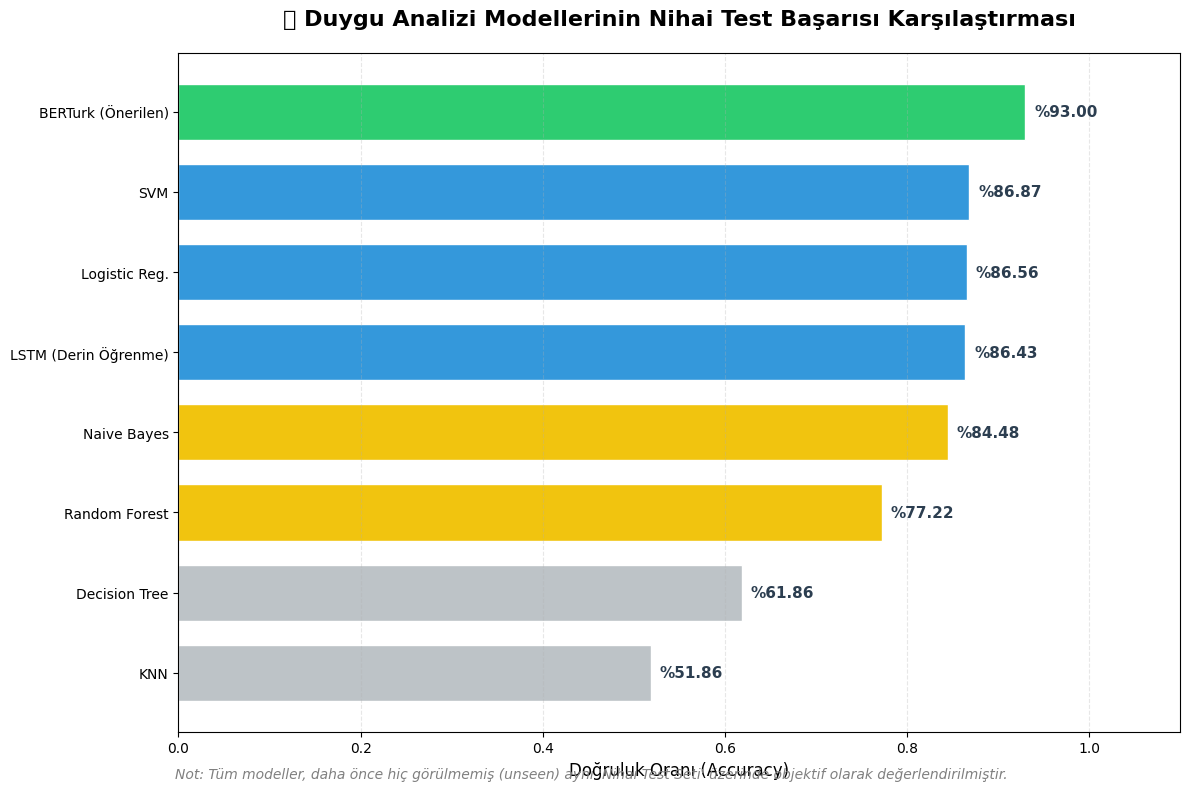

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

results = {
    "Model": [
        "KNN",
        "Decision Tree",
        "Random Forest",
        "Naive Bayes",
        "LSTM (Derin Öğrenme)",
        "Logistic Reg.",
        "SVM",
        "BERTurk (Önerilen)"
    ],
    "Accuracy": [
        0.5186, # KNN çıktından: %51.86
        0.6186, # Decision Tree çıktından: %61.86
        0.7722, # Random Forest çıktından: %77.22
        0.8448, # Naive Bayes çıktından: %84.48
        0.8643, # LSTM çıktından: %86.43
        0.8656, # Logistic Reg. çıktından: %86.56
        0.8687, # SVM çıktından: %86.87
        0.9300  # BERT (Nihai Test Raporu) çıktından: %93.00
    ]
}

df_results = pd.DataFrame(results).sort_values(by="Accuracy", ascending=True)

plt.figure(figsize=(12, 8))

colors = []
for model in df_results["Model"]:
    if "BERTurk" in model:
        colors.append('#2ecc71')
    elif "LSTM" in model or "SVM" in model or "Logistic" in model:
        colors.append('#3498db')
    elif "Naive" in model or "Forest" in model:
        colors.append('#f1c40f')
    else:
        colors.append('#bdc3c7')

bars = plt.barh(df_results["Model"], df_results["Accuracy"], color=colors, edgecolor='white', height=0.7)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01,
             bar.get_y() + bar.get_height()/2,
             f'%{width*100:.2f}',
             ha='left', va='center', fontsize=11, fontweight='bold', color='#2c3e50')

plt.title("📊 Duygu Analizi Modellerinin Nihai Test Başarısı Karşılaştırması", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Doğruluk Oranı (Accuracy)", fontsize=12)
plt.xlim(0, 1.1)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.figtext(0.15, 0.02,
            "Not: Tüm modeller, daha önce hiç görülmemiş (unseen) aynı 'Nihai Test Seti' üzerinde objektif olarak değerlendirilmiştir.",
            fontsize=10, style='italic', color='gray')

plt.tight_layout()
plt.show()

In [ ]:
!pip install spotipy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.4/404.4 kB 41.2 MB/s eta 0:00:00


In [ ]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained("dbmdz/bert-base-turkish-cased")
tokenizer.save_pretrained("/content/turkish_emotion_bert_pytorch_final")


('/content/turkish_emotion_bert_pytorch_final/tokenizer_config.json',
 '/content/turkish_emotion_bert_pytorch_final/tokenizer.json')

In [ ]:
best_model_path = "turkish_emotion_bert_pytorch_final"

tokenizer.save_pretrained(best_model_path)

print(f"✅ Tokenizer başarıyla '{best_model_path}' klasörüne eklendi!")

✅ Tokenizer başarıyla 'turkish_emotion_bert_pytorch_final' klasörüne eklendi!
🎉 Artık bu klasörü indirip projenin her yerinde kullanabilirsin.


In [ ]:
from transformers import BertTokenizer, BertForSequenceClassification

model_path = "/content/turkish_emotion_bert_pytorch_final"

tokenizer_loaded = BertTokenizer.from_pretrained(model_path)
model_loaded = BertForSequenceClassification.from_pretrained(model_path)

print("🔥 Model ve tokenizer başarıyla yüklendi!")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

🔥 Model ve tokenizer başarıyla yüklendi!


In [ ]:
# =============================================================================
# 🎧 AKILLI DUYGU DURUMU DESTEK PLATFORMU
# =============================================================================

import torch
from transformers import BertTokenizer, BertForSequenceClassification
from IPython.display import display, HTML, Javascript
from google.colab import output, userdata
import random
import spotipy
from spotipy.oauth2 import SpotifyClientCredentials
import requests
import csv
import os
import datetime
import sys

# ===============================
# 1️⃣ AYARLAR, LOGLAMA VE GÜVENLİK
# ===============================
print("⚙️ Sistem başlatılıyor...")

model_path = "/content/turkish_emotion_bert_pytorch_final"

try:
    client_id = userdata.get('SPOTIFY_ID')
    client_secret = userdata.get('SPOTIFY_SECRET')

    if not client_id or not client_secret:

        client_id = "MANUEL_GIRIS_YAPILABILIR"
        client_secret = "MANUEL_GIRIS_YAPILABILIR"
        if client_id == "MANUEL_GIRIS_YAPILABILIR":
             pass

    print("✅ Spotify API anahtarları kontrol edildi.")

except Exception as e:
    client_id = None
    client_secret = None
    print("\n⚠️ UYARI: Spotify API anahtarları 'Secrets' içinde bulunamadı!")

# ---  Geri Bildirim Dosyası ---
LOG_FILE = "kullanici_geri_bildirimleri.csv"

if not os.path.exists(LOG_FILE):
    with open(LOG_FILE, mode='w', newline='', encoding='utf-8') as file:
        writer = csv.writer(file)
        writer.writerow(["Tarih", "Girdi", "Mod", "Guven", "Oy"])

session_data = {"text": "", "mood": "", "conf": ""}

def geri_bildirim_kaydet(oy_tipi):
    zaman = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    try:
        with open(LOG_FILE, mode='a', newline='', encoding='utf-8') as file:
            writer = csv.writer(file)
            writer.writerow([zaman, session_data["text"], session_data["mood"], session_data["conf"], oy_tipi])
    except Exception as e:
        print(f"Log hatası: {e}")

output.register_callback('notebook.GeriBildirim', geri_bildirim_kaydet)

# ===============================
# 2️⃣ MODEL YÜKLEME 
# ===============================
try:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tokenizer_loaded = BertTokenizer.from_pretrained(model_path)
    model_loaded = BertForSequenceClassification.from_pretrained(model_path)
    model_loaded.to(device)
    model_loaded.eval()
    print(f"✅ %93 Başarı Oranlı BERTurk Modeli Aktif. (Cihaz: {device})")
except Exception as e:
    print(f"❌ Model yüklenemedi! Yol: {model_path}")

id2label_loaded = {0: 'Anger', 1: 'Disgust', 2: 'Fear', 3: 'Happy', 4: 'Sadness', 5: 'Surprise'}

# ===============================
# 3️⃣ SPOTIFY BAĞLANTISI
# ===============================
try:
    if client_id and client_secret and client_id != "MANUEL_GIRIS_YAPILABILIR":
        auth_manager = SpotifyClientCredentials(client_id=client_id, client_secret=client_secret)
        sp = spotipy.Spotify(auth_manager=auth_manager)
        print("✅ Spotify bağlantısı kuruldu.")
    else:
        sp = None
        print("⚠️ Spotify devre dışı (Anahtarlar eksik veya hatalı).")
except Exception as e:
    sp = None
    print(f"⚠️ Spotify bağlantı hatası: {e}")



# ==========================================
# 🧠 4️⃣ GELİŞMİŞ DUYGU ANALİZİ 
# ==========================================
def gelismis_duygu_analizi(metin, model, tokenizer):
    metin_lower = metin.lower()

    inputs = tokenizer(metin, return_tensors="pt", truncation=True, padding=True, max_length=128).to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=1).cpu().numpy()[0]
        pred_idx = int(probs.argmax())
        bert_label = id2label_loaded[pred_idx]
        confidence = float(probs[pred_idx])

    # --- ANAHTAR KELİME LİSTELERİ ---
    negation_keywords = ["iyi hissetmiyorum", "iyi değilim", "keyfim yok", "mutlu değilim", "tadım yok", "moralim bozuk", "kötü hissediyorum", "berbat"]
    tired_keywords = ["yorgun", "bitkin", "uyku", "halsiz", "pilim", "tükendim", "gücüm kalmadı", "halim yok", "pestil"]
    stressed_keywords = ["stres", "gergin", "daral", "bunal", "of", "baskı", "panik"]
    bored_keywords = ["sıkıldım", "vasat", "eh işte", "sıradan", "monoton", "yapacak bir şey yok"]
    excited_keywords = ["heyecan", "yerimde duramı", "kıpır kıpır", "sabırsız", "iple çekiyorum"]
    confusion_keywords = ["bilmiyorum", "emin değilim", "kararsızım", "anlamadım", "ne hissettiğimi", "bilmem", "karışık"]
    fear_keywords = ["sunum", "heyecan", "titriyor", "korkuyorum", "panik", "unutmuşum", "eyvah"]
    complex_markers = ["hem", "ama", "fakat", "garip hissediyorum", "ancak", "yine de"]
    has_dual_hem = "hem" in metin_lower and "hem" in metin_lower[metin_lower.find("hem")+1:]
    has_complex_feel = any(x in metin_lower for x in ["garip hissediyorum", "karışık hissediyorum"])

    if has_dual_hem or has_complex_feel or (any(x in metin_lower for x in complex_markers) and confidence < 0.60):
        final_mood = "Complex"
        display_mood = "Karmaşık Duygular 🤔"

    
    elif any(x in metin_lower for x in fear_keywords):
        final_mood = "Fear"
        display_mood = "Endişeli / Heyecanlı 😨"
    elif any(x in metin_lower for x in negation_keywords):
        final_mood = "Sadness"
        display_mood = "Üzgün / Keyifsiz 😔"
    elif any(x in metin_lower for x in tired_keywords):
        final_mood = "Tired"
        display_mood = "Yorgun & Bitkin 😴"
    elif any(x in metin_lower for x in stressed_keywords):
        final_mood = "Stressed"
        display_mood = "Gergin & Stresli 😫"
    elif any(x in metin_lower for x in excited_keywords):
        final_mood = "Excited"
        display_mood = "Heyecanlı & Enerjik 🤩"
    elif any(x in metin_lower for x in confusion_keywords) or confidence < 0.50:
        final_mood = "Complex"
        display_mood = "Karmaşık Duygular 🤔"

    
    else:
        final_mood = bert_label

        mood_mapping = {
            "Happy": "Mutlu 😊",
            "Sadness": "Üzgün 😔",
            "Anger": "Kızgın 😠",
            "Fear": "Endişeli / Korkmuş 😨",
            "Surprise": "Şaşkın 😲",
            "Disgust": "Rahatsız Olmuş 🤢"
        }
        display_mood = mood_mapping.get(bert_label, bert_label)

    return final_mood, display_mood, confidence

# ================================
# 🎵 5️⃣ MÜZİK ÖNERİSİ 
# ================================
def spotifydan_muzik_oner(mood):
    if sp is None: return None

    queries = {
        "Happy": ["Yalın", "Edis", "Kenan Doğulu", "Tarkan", "Sertab Erener"],
        "Excited": ["KÖFN", "Hadise", "Murat Boz", "Gülşen", "Mabel Matiz"],
        "Sadness": ["Pinhani", "Duman", "Canozan", "Sezen Aksu", "Müslüm Gürses"],
        "Anger": ["Mor ve Ötesi", "Athena", "MaNga", "Hayko Cepkin"],
        "Tired": ["Deniz Tekin", "Kalben", "Yüzyüzeyken Konuşuruz", "Adamlar"],
        "Complex": ["Dolu Kadehi Ters Tut", "Büyük Ev Ablukada", "Mabel Matiz", "Gaye Su Akyol"],
        "Stressed": ["Ludovico Einaudi", "Chopin", "Fazıl Say"],
        "Fear": ["Evgeny Grinko", "Sakinleştirici Piyano", "Nature Focus"]
    }

    query_list = queries.get(mood, ["Türkçe Pop"])
    target_artist_name = random.choice(query_list)

    try:
       
        artist_search = sp.search(q=f"artist:{target_artist_name}", type="artist", limit=1)

        if artist_search['artists']['items']:
            artist_id = artist_search['artists']['items'][0]['id']

            
            top_tracks = sp.artist_top_tracks(artist_id, country='TR')

            if top_tracks['tracks']:
                
                clean_tracks = [
                    t for t in top_tracks['tracks']
                    if not any(x in t['name'].lower() for x in ["ninni", "çocuk", "bebek", "lullaby", "dandini", "uyusun"])
                ]

                
                track = random.choice(clean_tracks[:min(3, len(clean_tracks))])

                return {
                    "name": track['name'],
                    "artist": track['artists'][0]['name'],
                    "link": track['external_urls']['spotify'],
                    "image": track['album']['images'][0]['url']
                }

        
        search_query = f"{target_artist_name} NOT ninni NOT çocuk NOT kids"
        results = sp.search(q=search_query, type="track", limit=5, market="TR")
        if results['tracks']['items']:
            track = results['tracks']['items'][0]
            return {
                "name": track['name'], "artist": track['artists'][0]['name'],
                "link": track['external_urls']['spotify'], "image": track['album']['images'][0]['url']
            }

    except Exception as e:
        
        pass

    return None
# ===============================
# 📚 6️⃣ KİTAP ÖNERİSİ 
# ===============================
def kitap_oner(mood):
    
    konular = {
        "Happy": ["Modern Türk Edebiyatı Mizah", "Sürükleyici Macera Romanları", "Mutluluk Veren Kitaplar"],
        "Sadness": ["Psikolojik Dram Romanları", "Sabahattin Ali Eserleri", "Duygusal Türk Klasikleri"],
        "Anger": ["Modern Felsefe Romanları", "Stoacılık Üzerine Kurgu", "Politik Romanlar"],
        "Fear": ["Polisiye Gerilim Romanları", "Gizemli Hikayeler", "Korku Edebiyatı Klasikleri"],
        "Disgust": ["Distopya Romanları", "Toplum Eleştirisi Kurgu", "Yeraltı Edebiyatı Romanları"],
        "Surprise": ["Bilim Kurgu Klasikleri", "Fantastik Türk Edebiyatı", "Sürpriz Sonlu Romanlar"],
        "Tired": ["Modern Öykü Antolojisi", "Kısa Hikaye Kitapları", "Dinlendirici Eserler"],
        "Stressed": ["Kişisel Gelişim Kurgu", "Doğa Yazıları Edebiyat", "Sakinleştirici Romanlar"],
        "Complex": ["Oğuz Atay Tutunamayanlar", "Hakan Günday Az", "Albert Camus Yabancı", "Varoluşçu Edebiyat Roman"],
        "Excited": ["Sürükleyici Bilim Kurgu", "Başarı Odaklı Romanlar", "Girişimcilik Hikayeleri"],
        "Bored": ["Popüler Polisiye Romanlar", "Çok Satan Romanlar", "Sürükleyici Macera"]
    }

    secilen_konu_listesi = konular.get(mood, ["Modern Türk Edebiyatı"])
    konu = random.choice(secilen_konu_listesi)

    try:
        
        start_index = random.randint(0, 5)

        url = f"https://www.googleapis.com/books/v1/volumes?q={konu}&printType=books&subject:fiction&langRestrict=tr&maxResults=10&startIndex={start_index}&orderBy=relevance"

        resp = requests.get(url).json()

        if "items" in resp:
            
            kitap_verisi = random.choice(resp["items"][:5])
            kitap = kitap_verisi["volumeInfo"]

            
            resim = kitap.get("imageLinks", {}).get("thumbnail", "https://via.placeholder.com/128x192?text=Kitap+Kapak")

            authors = kitap.get("authors", ["Bilinmeyen Yazar"])
            authors_str = ", ".join(authors) if isinstance(authors, list) else str(authors)

            return {
                "title": kitap.get("title", "Bilinmeyen Eser"),
                "authors": authors_str,
                "infoLink": kitap.get("previewLink", "#"),
                "thumbnail": resim
            }

        else:
            url_fallback = f"https://www.googleapis.com/books/v1/volumes?q={konu}+roman&printType=books&langRestrict=tr&maxResults=5"
            resp_f = requests.get(url_fallback).json()
            if "items" in resp_f:
                kitap_f = resp_f["items"][0]["volumeInfo"]
                return {
                    "title": kitap_f.get("title", "Bilinmeyen Roman"),
                    "authors": ", ".join(kitap_f.get("authors", ["Yazar Belirtilmemiş"])),
                    "infoLink": kitap_f.get("previewLink", "#"),
                    "thumbnail": kitap_f.get("imageLinks", {}).get("thumbnail", "https://via.placeholder.com/128x192?text=Roman")
                }

    except Exception as e:
        print(f"⚠️ Kitap Öneri Hatası: {e}")

    return None
# ===============================
# 🍔 7️⃣ YEMEK ÖNERİSİ 
# ===============================
def yemek_oner(mood):
    
    cat_map = {
        "Happy": "Seafood",
        "Sadness": "Dessert",
        "Anger": "Beef",
        "Fear": "Breakfast",
        "Disgust": "Vegetarian",
        "Surprise": "Pasta",
        "Tired": "Chicken",
        "Stressed": "Pasta",
        "Complex": "Dessert",  
        "Excited": "Starter",
        "Bored": "Dessert"
    }

    is_turkish_mode = random.choice([True, False])

    if mood in ["Sadness", "Bored", "Complex"]:
        
        url = "https://www.themealdb.com/api/json/v1/1/filter.php?c=Dessert"
        mutfak_turu = "Seni Şımartacak Tatlılar 🍰"
    elif is_turkish_mode:
        url = "https://www.themealdb.com/api/json/v1/1/filter.php?a=Turkish"
        mutfak_turu = "Geleneksel Türk Mutfağı 🇹🇷"
    else:
        category = cat_map.get(mood, "Side")
        url = f"https://www.themealdb.com/api/json/v1/1/filter.php?c={category}"
        mutfak_turu = f"Dünya Mutfağı ({category}) 🌍"

    try:
        resp = requests.get(url).json()
        meals = resp.get("meals")
        if meals:
            
            meal_summary = random.choice(meals[:10] if len(meals) > 10 else meals)

            det_resp = requests.get(f"https://www.themealdb.com/api/json/v1/1/lookup.php?i={meal_summary['idMeal']}").json()
            meal = det_resp['meals'][0]

            youtube_link = meal.get('strYoutube')
            final_link = youtube_link if youtube_link and str(youtube_link).strip() != "" else f"https://www.google.com/search?q={meal['strMeal']}+tarifi"

            return {
                "name": meal['strMeal'],
                "image": meal['strMealThumb'],
                "category": mutfak_turu,
                "link": final_link
            }
    except Exception as e:
        print(f"Yemek Hatası: {e}")
    return None

# ===============================
# 🎨 8️⃣ TEMA & ARAYÜZ
# ===============================
def get_theme_assets(mood_code, mood_text):
    themes = {
        "Happy":    {"bg": "linear-gradient(120deg, #f6d365 0%, #fda085 100%)", "color": "#d35400", "msg": "Harika görünüyorsun! Enerjini koruyalım."},
        "Excited":  {"bg": "linear-gradient(120deg, #84fab0 0%, #8fd3f4 100%)", "color": "#16a085", "msg": "Enerjin bulaşıcı! Haydi harekete geçelim."},
        "Tired":    {"bg": "linear-gradient(to top, #cfd9df 0%, #e2ebf0 100%)", "color": "#546e7a", "msg": "Dünyayı kurtarmak zorunda değilsin. Dinlen."},
        "Stressed": {"bg": "linear-gradient(120deg, #fccb90 0%, #d57eeb 100%)", "color": "#8e44ad", "msg": "Derin bir nefes al. Her şey kontrol altında."},
        "Sadness":  {"bg": "linear-gradient(120deg, #a1c4fd 0%, #c2e9fb 100%)", "color": "#2980b9", "msg": "Hüzün de bir misafirdir. Yalnız değilsin."},
        "Anger":    {"bg": "linear-gradient(120deg, #ff9a9e 0%, #fecfef 99%, #fecfef 100%)", "color": "#c0392b", "msg": "Sakinleşmek güçtür. Kendine zaman ver."},
        "Fear":     {"bg": "linear-gradient(to top, #e6e9f0 0%, #eef1f5 100%)", "color": "#7f8c8d", "msg": "Güvendesin. Bu his geçici."},
        "Complex":  {"bg": "linear-gradient(135deg, #f5f7fa 0%, #c3cfe2 100%)", "color": "#34495e", "msg": "Bazen hisler karışır. Akışına bırak."},
        "Surprise": {"bg": "linear-gradient(120deg, #e0c3fc 0%, #8ec5fc 100%)", "color": "#6c5ce7", "msg": "Hayat sürprizlerle dolu!"},
        "Disgust":  {"bg": "linear-gradient(120deg, #d4fc79 0%, #96e6a1 100%)", "color": "#27ae60", "msg": "Taze bir başlangıç yapalım."}
    }
    t = themes.get(mood_code, themes["Happy"])
    return t["bg"], t["color"], t["msg"]

# ===============================
# 🚀 9️⃣ ANA ÇALIŞTIRMA (MAIN)
# ===============================
user_text = input("\n📝 Bugün nasıl hissediyorsun? (Dürüst ol): ")

# 1. Analiz
mood_code, mood_text, conf = gelismis_duygu_analizi(user_text, model_loaded, tokenizer_loaded)

# 2. Verileri Kaydet
session_data["text"] = user_text; session_data["mood"] = mood_text; session_data["conf"] = f"%{conf*100:.1f}"

print(f"\n🧠 Analiz Sonucu: {mood_text} (Güven: %{conf*100:.1f}) - Kod: {mood_code}")

# 3. Önerileri Getir
music = spotifydan_muzik_oner(mood_code)
book = kitap_oner(mood_code)
food = yemek_oner(mood_code)

# 4. Arayüzü Çiz
if music and book and food:
    bg_gradient, accent_color, message = get_theme_assets(mood_code, mood_text)
    html_code = f"""
    <!DOCTYPE html>
    <html>
    <head>
    <link href="https://fonts.googleapis.com/css2?family=Outfit:wght@300;400;600;800&display=swap" rel="stylesheet">
    <style>
        body {{ font-family: 'Outfit', sans-serif; margin: 0; padding: 0; }}

        .dashboard {{
            background: {bg_gradient};
            min-height: 620px;
            padding: 50px;
            border-radius: 24px;
            color: #333;
            box-shadow: 0 20px 60px rgba(0,0,0,0.15);
        }}

        .header {{ text-align: center; margin-bottom: 40px; }}
        .mood-title {{ font-size: 3.5rem; font-weight: 800; color: {accent_color}; margin: 0; text-shadow: 0 2px 20px rgba(255,255,255,0.6); }}
        .subtitle {{ font-size: 1.3rem; color: #444; background: rgba(255,255,255,0.7); display: inline-block; padding: 8px 30px; border-radius: 50px; margin-top: 15px; }}

        /* Kartların Yan Yana Dizilmesi */
        .cards-wrapper {{
            display: flex;
            justify-content: center;
            gap: 20px;
            flex-wrap: wrap;
            align-items: stretch;
        }}

        .card {{
            background: rgba(255, 255, 255, 0.9);
            backdrop-filter: blur(20px);
            border-radius: 28px;
            padding: 20px;
            flex: 1 1 280px;
            max-width: 320px;
            height: auto;
            text-align: center;
            border: 1px solid rgba(255,255,255,0.8);
            box-shadow: 0 10px 30px rgba(0,0,0,0.08);
            display: flex;
            flex-direction: column;
        }}

        /* --- RESİM BOYUTU ARTIRILDI --- */
        .card-img {{
            width: 100%;
            height: 260px;  /* 200px'den 260px'e çıkarıldı */
            object-fit: cover;
            border-radius: 15px;
            margin-bottom: 15px;
        }}

        .book-fit {{ object-fit: contain; background: transparent; }}

        .category-tag {{ font-size: 0.75rem; text-transform: uppercase; letter-spacing: 1.5px; color: #888; font-weight: 800; margin-bottom: 10px; display: block; }}
        .item-title {{ font-size: 1.2rem; font-weight: 700; margin: 5px 0; color: #2d3436; line-height: 1.3; }}
        .item-sub {{ font-size: 0.9rem; color: #636e72; margin-bottom: 10px; }}

        .btn-base {{
            display: flex;
            align-items: center;
            justify-content: center;
            gap: 10px;
            padding: 14px 20px;
            border-radius: 16px;
            text-decoration: none;
            font-weight: 600;
            font-size: 0.95rem;
            transition: all 0.2s ease;
            box-shadow: 0 4px 15px rgba(0,0,0,0.1);
            color: white;
            margin-top: 20px;
        }}

        .btn-base:hover {{ transform: scale(1.05); }}
        .btn-spotify {{ background-color: #1DB954; }}
        .btn-book {{ background-color: #4285F4; }}
        .btn-food {{ background-color: #FF6D00; }}
        .btn-icon {{ width: 20px; height: 20px; fill: white; }}

        .feedback-area {{ margin-top: 50px; text-align: center; background: rgba(255,255,255,0.6); padding: 15px 30px; border-radius: 50px; display: inline-block; left: 50%; transform: translateX(-50%); position: relative; }}
        .fb-text {{ font-size: 0.9rem; color: #555; margin-bottom: 10px; font-weight: 600; }}
        .fb-btn {{ cursor: pointer; border: none; padding: 8px 20px; border-radius: 20px; font-family: 'Outfit', sans-serif; font-weight: 700; font-size: 0.9rem; margin: 0 8px; transition: all 0.3s ease; }}
        .fb-like {{ background: white; color: #27ae60; border: 2px solid #27ae60; }} .fb-like:hover {{ background: #27ae60; color: white; }}
        .fb-dislike {{ background: white; color: #c0392b; border: 2px solid #c0392b; }} .fb-dislike:hover {{ background: #c0392b; color: white; }}
        #fb-message {{ margin-top: 10px; font-weight: 700; color: {accent_color}; font-size: 0.9rem; opacity: 0; transition: opacity 0.5s ease; }}
    </style>
    </head>
    <body>
    <div class="dashboard">
        <div class="header">
            <h1 class="mood-title">{mood_text}</h1>
            <div class="subtitle">"{message}"</div>
            <div style="font-size:0.7rem; margin-top:15px; opacity:0.5; font-weight:600;">AI GÜVEN: %{conf*100:.1f}</div>
        </div>
        <div class="cards-wrapper">
            <div class="card">
                <div><span class="category-tag">MÜZİK TERAPİSİ</span><img src="{music['image']}" class="card-img"><div class="item-title">{music['name']}</div><div class="item-sub">{music['artist']}</div></div>
                <a href="{music['link']}" target="_blank" class="btn-base btn-spotify"><svg class="btn-icon" viewBox="0 0 24 24"><path d="M12 0C5.4 0 0 5.4 0 12s5.4 12 12 12 12-5.4 12-12S18.66 0 12 0zm5.521 17.34c-.24.359-.66.48-1.021.24-2.82-1.74-6.36-2.101-10.561-1.141-.418.122-.779-.179-.899-.539-.12-.421.18-.78.54-.9 4.56-1.021 8.52-.6 11.64 1.32.42.18.479.659.301 1.02zm1.44-3.3c-.301.42-.841.6-1.262.3-3.239-1.98-8.159-2.58-11.939-1.38-.479.12-1.02-.12-1.14-.6-.12-.48.12-1.021.6-1.141C9.6 9.9 15 10.561 18.72 12.84c.361.181.54.78.241 1.2zm.12-3.36C15.24 8.4 8.82 8.16 5.16 9.301c-.6.179-1.2-.181-1.38-.721-.18-.601.18-1.2.72-1.381 4.26-1.26 11.28-1.02 15.721 1.621.539.3.719 1.02.419 1.56-.299.421-1.02.599-1.559.3z"/></svg>Spotify'da Dinle</a>
            </div>
            <div class="card">
                <div><span class="category-tag">ZİHİN BESİNİ</span><img src="{book['thumbnail']}" class="card-img book-fit"><div class="item-title">{book['title']}</div><div class="item-sub">{book['authors']}</div></div>
                <a href="{book['infoLink']}" target="_blank" class="btn-base btn-book"><svg class="btn-icon" viewBox="0 0 24 24"><path d="M18 2H6c-1.1 0-2 .9-2 2v16c0 1.1.9 2 2 2h12c1.1 0 2-.9 2-2V4c0-1.1-.9-2-2-2zM6 4h5v8l-2.5-1.5L6 12V4z"/></svg>Kitabı İncele</a>
            </div>
            <div class="card">
                <div><span class="category-tag">MUTLULUK TARİFİ</span><img src="{food['image']}" class="card-img"><div class="item-title">{food['name']}</div><div class="item-sub">{food['category']}</div></div>
                <a href="{food['link']}" target="_blank" class="btn-base btn-food"><svg class="btn-icon" viewBox="0 0 24 24"><path d="M11 9H9V2H7v7H5V2H3v7c0 2.12 1.66 3.84 3.75 3.97V22h2.5v-9.03C11.34 12.84 13 11.12 13 9V2h-2v7zm5-3v8h2.5v8H21V2c-2.76 0-5 2.24-5 4z"/></svg>Tarife Git</a>
            </div>
        </div>
        <div class="feedback-area">
            <div class="fb-text">Bu öneriler moduna iyi geldi mi?</div>
            <button class="fb-btn fb-like" onclick="sendFeedback('Olumlu')">👍 Evet</button>
            <button class="fb-btn fb-dislike" onclick="sendFeedback('Olumsuz')">👎 Hayır</button>
            <div id="fb-message">Geri bildiriminiz kaydedildi! ✅</div>
        </div>
    </div>
    <script>
        function sendFeedback(type) {{
            google.colab.kernel.invokeFunction('notebook.GeriBildirim', [type], {{}});
            document.getElementById('fb-message').style.opacity = '1';
            var btns = document.getElementsByClassName('fb-btn');
            for(var i=0; i<btns.length; i++) {{ btns[i].style.pointerEvents = 'none'; btns[i].style.opacity = '0.5'; }}
        }}
    </script>
    </body>
    </html>
    """
    display(HTML(html_code))
else:
    print("⚠️ Öneriler oluşturulamadı. Lütfen internet bağlantısını veya API anahtarlarını kontrol edin.")

⚙️ Sistem başlatılıyor...
✅ Spotify API anahtarları kontrol edildi.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ %93 Başarı Oranlı BERTurk Modeli Aktif. (Cihaz: cuda)
✅ Spotify bağlantısı kuruldu.

📝 Bugün nasıl hissediyorsun? (Dürüst ol): çok mutluyum proje sonunda tamamlanıyor

🧠 Analiz Sonucu: Mutlu 😊 (Güven: %99.9) - Kod: Happy
